In [3]:
!pip install tellurium

In [4]:
import tellurium as te

import numpy as np
from numpy.linalg import matrix_rank

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from mpl_toolkits import mplot3d

import numpy as np
import io
import os
import pandas as pd

rgb_orange = (255, 95, 5)
rgb_blue = (0, 159, 212)
rgb_harvest = (252, 179, 22)
rgb_orange_norm = tuple(c / 255.0 for c in rgb_orange)
rgb_blue_norm = tuple(c / 255.0 for c in rgb_blue)
rgb_harvest_norm = tuple(c / 255.0 for c in rgb_harvest)

from matplotlib.colors import LogNorm

# Example 5.3:  T-cell activation with no IFF

## Kinetic proofreading step

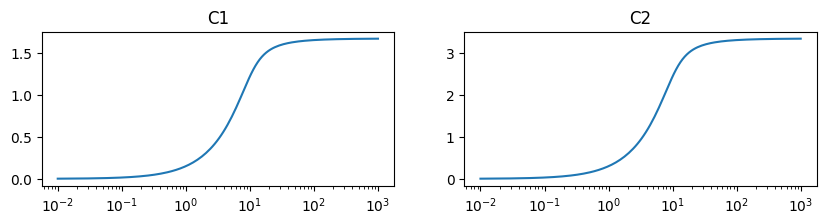

In [5]:
tfinal = 100;
n_timestep = 500;
err_tol = 1e-6;
tfinal_relaxation = 500;

umin = 1e-2
umax = 1e3
usteps = 150;

LT_array = np.logspace(np.log10(umin),np.log10(umax),usteps);
RT = 10;

## output arrays
no_of_sites = 2;
no_of_species = no_of_sites + 3;
TCR_output_array = np.zeros((no_of_sites, len(LT_array)))

ss_error_array = np.zeros(len(LT_array))



## Model:
ant_str_KPR =  """
  species L, R, C0, C1, C2

  ## == spontaneous conversions ==
  bind:  L + R  -> C0;  kon*L*R;
  off0:  C0 -> L + R;   l0*C0;
  ph0:   C0 -> C1;      kp0*C0;
  off1:  C1 -> L + R;   l1*C1;
  ph1:   C1 -> C2;      kp1*C1;
  off2:  C2 -> L + R;   l2*C2;


  ## == parameters ==
  kon = 1; kp0 = 1; kp1 = 2;
  l0 = 1; l1 = 1; l2 = 1;

  ## == IC ==
  R = 10;
"""


r = te.loada(ant_str_KPR)


for ii in range(len(LT_array)):
  ## setting initial conditions (TCR to u_array, Xi = 1, Xip = 0)
  r.conservedMoietyAnalysis = False
  r.resetAll()
  r.setValue('init(R)', RT)
  r.setValue('init(L)', LT_array[ii])
  r.setValue('init(C0)', 0); r.setValue('init(C1)', 0); r.setValue('init(C2)', 0);
  r.conservedMoietyAnalysis = True


  ## run simulation
  results = r.simulate(0,tfinal,n_timestep)


  ## Checking whether at steady states
  species_list = results.colnames[1:]
  ss_values = results[-1, 1:]; ## ss val from numerical simulation
  r.steadyState()
  r.getFloatingSpeciesConcentrations()
  r.getReactionRates()

  r.steadyStateSelections = species_list
  error = np.linalg.norm(r.getSteadyStateValues() - ss_values)/no_of_species
  ss_error_array[ii] = error;
  if error > err_tol: ## simulation to longer time if not yet at steady state
    results = r.simulate(0,tfinal_relaxation,n_timestep)
    ss_values = results[-1, 1:]
    r.steadyState()
    r.getFloatingSpeciesConcentrations()
    r.getReactionRates()
    r.steadyStateSelections = species_list
    error = np.linalg.norm(r.getSteadyStateValues() - ss_values)/no_of_species
    if error > err_tol:  ## return error msg if still not at steady state
        print('Current u (LT) value = ', LT_array[ii])
        print('ss values read from results (num. sim.): ', ss_values)
        print('ss values from getSteadyStateValues: ', r.getSteadyStateValues())
        raise RuntimeError(f'Steady state not reached: error = {error:.3e} > tol = {err_tol:.1e}')


  ## save steady state data to array and update data for next run
  TCR_output_array[:, ii] = [r.C1, r.C2];




## plot of response curves of TCR-complexes
fig, ax = plt.subplots(1,no_of_sites, figsize = (2*no_of_species,2))
for ii in range(no_of_sites):
  ax[ii].plot(LT_array, TCR_output_array[ii,:], label=f'C{ii+1}')
  ax[ii].set_title(f'C{ii+1}')
  ax[ii].set_xscale('log')


## Downstream signalling

In [6]:
'''model and parameter definition'''

tfinal = 100;
n_timestep = 500; #8000;
err_tol = 1e-6;
tfinal_relaxation = 500;

# umin = 0.1 #1e-4
# umax = 10
# usteps = 10;
# u_array = np.logspace(np.log10(umin),np.log10(umax),usteps);

u_array = TCR_output_array[1,:] ## index 1 uses C2


## output arrays
no_of_species = 5;
no_of_rxns = 20;
X_output_array = np.zeros((no_of_species, len(u_array)))
Xp_output_array = np.zeros((no_of_species, len(u_array)))
evals_output_array = np.zeros((no_of_species,len(u_array)), dtype=complex)

fluxes_output_array = np.zeros((no_of_rxns, len(u_array))) ## to check for steady states
ss_error_array = np.zeros(len(u_array))



## Model:
ant_str =  """
  species TCR, X1, X1p, X2, X2p, X3, X3p, X4, X4p, X5, X5p

  ## == spontaneous conversions ==
  Ja1: X1 -> X1p; g1*X1;    Jd1: X1p -> X1; d1*X1p;
  Ja2: X2 -> X2p; g2*X2;    Jd2: X2p -> X2; d2*X2p;
  Ja3: X3 -> X3p; g3*X3;    Jd3: X3p -> X3; d3*X3p;
  Ja4: X4 -> X4p; g4*X4;    Jd4: X4p -> X4; d4*X4p;
  Ja5: X5 -> X5p; g5*X5;    Jd5: X5p -> X5; d5*X5p;

  ## == reactions ==
  # Input Ci -> X5
  aCX5: TCR + X5 -> TCR + X5p;  eta*TCR*X5;

  # X5 -| X1
  iX5X1: X5p + X1p -> X5p + X1; k51*X5p*X1p;

  # NFBL X1 |=> X2
  aX1X2: X1p + X2 -> X1p + X2p; k12*X1p*X2;
  iX2X1: X2p + X1p -> X2p + X1; k21*X2p*X1p;

  # PFBL X2 <=> X3
  aX2X3: X2p + X3 -> X2p + X3p; k23*X2p*X3;
  aX3X2: X3p + X2 -> X3p + X2p; k32*X3p*X2;

  # PFBL X2 |=| X4
  iX2X4: X2p + X4p -> X2p + X4; k24*X2p*X4p;
  iX4X2: X4p + X2p -> X4p + X2; k42*X4p*X2p;

  # PFBL X3 |=| X4
  iX3X4: X3p + X4p -> X3p + X4; k34*X3p*X4p;
  iX4X3: X4p + X3p -> X4p + X3; k43*X4p*X3p;



  ## == parameters ==
  g1 = 0.04;   d1 = 0.008;
  g2 = 0.008; d2 = 2.3;
  g3 = 0.025;  d3 = 0.05;
  g4 = 0.72;   d4 = 0.6;
  g5 = 0.001;  d5 = 1.0;

  eta = 0.05;
  k51 = 4;
  k12 = 6.7; k21 = 8.5;
  k23 = 1.05; k32 = 1.25;
  k24 = 63; k42 = 260;
  k34 = 54; k43 = 5.8;

  ## == IC ==
  X1 = 1;  X1p = 0;
  X2 = 1;  X2p = 0;
  X3 = 1;  X3p = 0;
  X4 = 1;  X4p = 0;
  X5 = 1;  X5p = 0;
"""


Initial total concentrations =  [1.0, 1.0, 1.0, 1.0, 1.0]


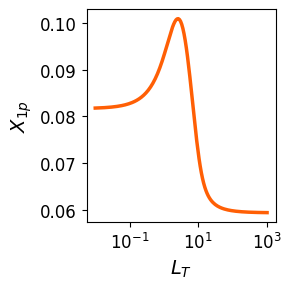

In [7]:
r = te.loada(ant_str)
r.setBoundary('TCR', True)
r.conservedMoietyAnalysis = True
X_ids = ['X1', 'X2', 'X3', 'X4', 'X5']
Xp_ids = ['X1p', 'X2p', 'X3p', 'X4p', 'X5p']

## initial total concentrations:
X1_total = r.X1 + r.X1p;  X2_total = r.X2 + r.X2p;
X3_total = r.X3 + r.X3p;  X4_total = r.X4 + r.X4p;  X5_total = r.X5 + r.X5p;
X_total = [X1_total, X2_total, X3_total, X4_total, X5_total];
print('Initial total concentrations = ', X_total)

## To save between runs
X1_prev = 1;  X1p_prev = 0;
X2_prev = 1;  X2p_prev = 0;
X3_prev = 1;  X3p_prev = 0;
X4_prev = 1;  X4p_prev = 0;
X5_prev = 1;  X5p_prev = 0;


for ii in range(len(u_array)):
  ## checking if conserved quantities held from previous loop
  X_prev = [X1_prev, X2_prev, X3_prev, X4_prev, X5_prev]
  Xp_prev = [X1p_prev, X2p_prev, X3p_prev, X4p_prev, X5p_prev]
  err_IC_totals = np.linalg.norm(np.array(X_prev) + np.array(Xp_prev) - np.array(X_total))
  if err_IC_totals > err_tol:
      print('Current u (KPR Ci) value = ', u_array[ii])
      raise RuntimeError(f'Conserved quantities violated: error = {err_IC_totals:.3e} > tol = {err_tol:.1e}')


  ## setting initial conditions (TCR to u_array, Xi = 1, Xip = 0)
  r.conservedMoietyAnalysis = False
  r.resetAll()
  r.setValue('init(TCR)', u_array[ii])
  for sid, val in zip(X_ids, X_prev):
    r.setValue(f'init({sid})', val)
  for sid, val in zip(Xp_ids, Xp_prev):
    r.setValue(f'init({sid})', val)
  r.conservedMoietyAnalysis = True
  # print('Previous X1p, X2p = ', r.X1p,  r.X2p)


  ## run simulation
  results = r.simulate(0,tfinal,n_timestep)


  ## Checking whether at steady states
  species_list = results.colnames[1:]
  ss_values = results[-1, 1:]; ## ss val from numerical simulation
  r.steadyState()
  r.getFloatingSpeciesConcentrations()
  r.getReactionRates()

  r.steadyStateSelections = species_list
  error = np.linalg.norm(r.getSteadyStateValues() - ss_values)/no_of_species
  ss_error_array[ii] = error;
  if error > err_tol: ## simulation to longer time if not yet at steady state
    results = r.simulate(0,tfinal_relaxation,n_timestep)
    ss_values = results[-1, 1:]
    r.steadyState()
    r.getFloatingSpeciesConcentrations()
    r.getReactionRates()
    r.steadyStateSelections = species_list
    error = np.linalg.norm(r.getSteadyStateValues() - ss_values)/no_of_species
    if error > err_tol:  ## return error msg if still not at steady state
        print('Current u (KPR Ci) value = ', u_array[ii])
        print('ss values read from results (num. sim.): ', ss_values)
        print('ss values from getSteadyStateValues: ', r.getSteadyStateValues())
        raise RuntimeError(f'Steady state not reached: error = {error:.3e} > tol = {err_tol:.1e}')


  ## save steady state data to array and update data for next run
  X_output_array[:, ii] = [r.X1, r.X2, r.X3, r.X4, r.X5];
  Xp_output_array[:, ii] = [r.X1p, r.X2p, r.X3p, r.X4p, r.X5p];

  X1_prev = r.X1;  X1p_prev = r.X1p;
  X2_prev = r.X2;  X2p_prev = r.X2p;
  X3_prev = r.X3;  X3p_prev = r.X3p;
  X4_prev = r.X4;  X4p_prev = r.X4p;
  X5_prev = r.X5;  X5p_prev = r.X5p;

  ## save eigenvalues data
  evals_output_array[:,ii] = np.linalg.eigvals(r.getReducedJacobian())


# ## rough plot of response curves
# fig, ax = plt.subplots(1,no_of_species, figsize = (2*no_of_species,2))
# for ii in range(no_of_species):
#   ax[ii].plot(u_array, Xp_output_array[ii,:], label=f'X{ii+1}p')
#   ax[ii].set_title(f'X{ii+1}p')
#   ax[ii].set_xscale('log')

fig, ax = plt.subplots(figsize=(3,3))
plt.plot(LT_array, Xp_output_array[0,:], color=rgb_orange_norm, linestyle='-', linewidth=2.5)
plt.xlabel('$L_T$', fontsize=14)
plt.ylabel('$X_{1p}$', fontsize=14)
ax.tick_params(axis="both", labelsize=12)
plt.xscale('log')
# plt.legend(fontsize=12)
plt.tight_layout()



### Eigenvalues

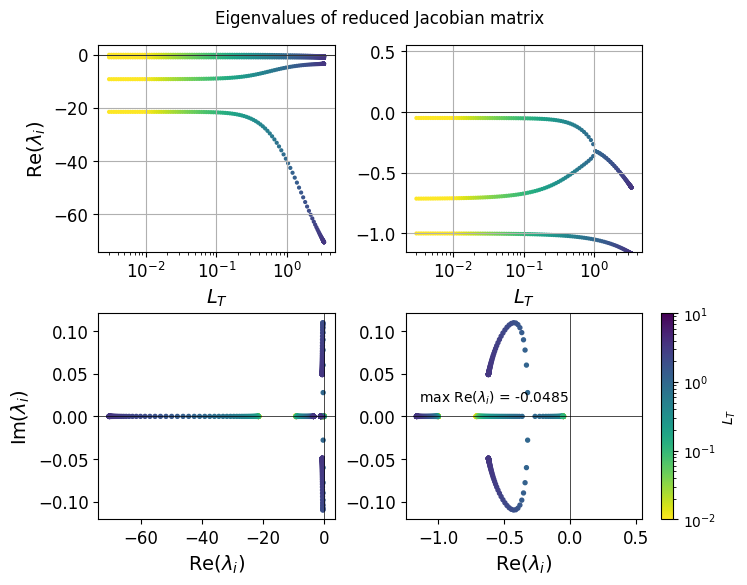

In [9]:

## eigenvalue plots:
fig, ax = plt.subplots(2, 2, figsize=(7.5, 6))
U = np.tile(u_array, no_of_species)

ev = evals_output_array.ravel()
max_re = np.max(ev.real)
axis_max = 0.05
axis_max2 = 0.1

ax[0,0].scatter(U, np.real(evals_output_array), c=U,cmap='viridis_r', s=4, norm=LogNorm(vmin=1e-2, vmax=1e1))
ax[0,0].set_xscale('log')
# ax[0,0].set_ylim([-19.5,4.5])
ax[0,0].grid(True)
ax[0,1].scatter(U, np.real(evals_output_array), c=U,cmap='viridis_r', s=4, norm=LogNorm(vmin=1e-2, vmax=1e1))
ax[0,1].set_xscale('log')
# ax[0,1].set_ylim([6*max_re,axis_max])
ax[0,1].set_ylim([-1.15,0.55])
ax[0,1].grid(True)
ax[0,0].axhline(0, color='k', lw=0.5)
ax[0,1].axhline(0, color='k', lw=0.5)
ax[0,0].axvline(0, color='k', lw=0.5)
ax[0,1].axvline(0, color='k', lw=0.5)
ax[0,0].set_xlabel('$L_T$', fontsize=14)
ax[0,0].set_ylabel(r'Re($\lambda_i$)', fontsize=14)
ax[0,1].set_xlabel('$L_T$', fontsize=14)
ax[0,0].tick_params(axis="both", labelsize=12)
ax[0,1].tick_params(axis="both", labelsize=12)


sc = ax[1,0].scatter(ev.real, ev.imag, c=U, cmap='viridis_r', s=8, norm=LogNorm(vmin=1e-2, vmax=1e1))
ax[1,0].axvline(0, color='k', lw=0.5)      # stability boundary
ax[1,0].axhline(0, color='k', lw=0.5)
ax[1,0].set_xlabel(r'Re($\lambda_i$)', fontsize=14)
# ax[1,0].set_xlim([-20,1])
ax[1,0].set_ylabel(r'Im($\lambda_i$)', fontsize=14)

sc = ax[1,1].scatter(ev.real, ev.imag, c=U, cmap='viridis_r', s=8, norm=LogNorm(vmin=1e-2, vmax=1e1))
ax[1,1].axvline(0, color='k', lw=0.5)      # stability boundary
ax[1,1].axhline(0, color='k', lw=0.5)
ax[1,1].set_xlabel(r'Re($\lambda_i$)', fontsize=14)
ax[1,1].set_xlim([-1.25,0.55])
# ax[1,1].set_ylim([-0.25,0.25])
ax[1,0].tick_params(axis="both", labelsize=12)
ax[1,1].tick_params(axis="both", labelsize=12)
cax = ax[1,1].inset_axes([1.08, 0, 0.05, 1])
cbar = fig.colorbar(sc, cax=cax, label='$L_T$')
fig.subplots_adjust(right=0.85, wspace=0.3, hspace=0.3)

ax[1,1].annotate(rf'max Re($\lambda_i$) = {max_re:.3g}', xy=(-0.005, 0),
                 xytext=(0, 10), textcoords='offset points',
                 ha='right', fontsize=10);
plt.suptitle('Eigenvalues of reduced Jacobian matrix', y=0.96)
fig.subplots_adjust(top=0.90)


plt.show()

# Example 5.4: Gene regulatory network with no IFF

In [15]:
no_of_species = 4;

tfinal = 100;
n_timestep = 500;
err_tol = 1e-6;
tfinal_relaxation = 500;

umax = 5;
u_array = np.linspace(0,umax,50);

X_output_array = np.zeros((no_of_species, len(u_array)))
evals_output_array = np.zeros((no_of_species,len(u_array)), dtype=complex)
ss_error_array = np.zeros(len(u_array))

ant_str = """
    species x1, x2, x3, x4

    J1:  -> x1; g1 - d1*x1;
    J2:  -> x2; g2 - d2*x2;
    J3:  -> x3; g3 - d3*x3;
    J4:  -> x4; g4 - d4*x4;

    au1: -> x1; eta*u;

    a12: -> x2; k12*x1^m12/(V12 + x1^m12);
    a23: -> x3; k23*x2^m23/(V23 + x2^m23);
    a32: -> x2; k32*x3^m32/(V32 + x3^m32);

    i21: -> x1; k21/(V21 + x2^m21);
    i14: -> x4; k14/(V14 + x1^m14);


    g1 = 1.3; g2 = 0.1; g3 = 0.1; g4 = 0.2;
    d1 = 5; d2 = 2; d3 = 1; d4 = 1;

    eta = 0.7;  u = 0;

    k12 = 2; V12 = 1; m12 = 6;
    k21 = 6; V21 = 1; m21 = 10;
    k23 = 2; V23 = 1; m23 = 6;
    k32 = 2; V32 = 1; m32 = 6;
    k14 = 5; V14 = 1; m14 = 4;

"""
r = te.loada(ant_str)
r.conservedMoietyAnalysis = True
X_ids = ['x1', 'x2', 'x3', 'x4']


## To save between runs
x1_prev = 1; x2_prev = 1; x3_prev  = 1; x4_prev  = 1;

for ii in range(len(u_array)):
  ## checking if conserved quantities held from previous loop
  X_prev = [x1_prev, x2_prev, x3_prev, x4_prev]

  ## setting initial conditions
  r.conservedMoietyAnalysis = False
  r.resetAll()
  r.setValue('u', u_array[ii])
  r.setValue('x1', x1_prev)
  r.setValue('x2', x2_prev)
  r.setValue('x3', x3_prev)
  r.setValue('x4', x4_prev)
  r.conservedMoietyAnalysis = True

  ## run simulation
  results = r.simulate(0,tfinal,n_timestep)

  ## Checking whether at steady states
  species_list = results.colnames[1:]
  ss_values = results[-1, 1:]; ## ss val from numerical simulation
  r.steadyState()
  r.getFloatingSpeciesConcentrations()
  r.getReactionRates()

  r.steadyStateSelections = species_list
  error = np.linalg.norm(r.getSteadyStateValues() - ss_values)/no_of_species
  ss_error_array[ii] = error;
  if error > err_tol: ## simulation to longer time if not yet at steady state
    results = r.simulate(0,tfinal_relaxation,n_timestep)
    ss_values = results[-1, 1:]
    r.steadyState()
    r.getFloatingSpeciesConcentrations()
    r.getReactionRates()
    r.steadyStateSelections = species_list
    error = np.linalg.norm(r.getSteadyStateValues() - ss_values)/no_of_species
    if error > err_tol:  ## return error msg if still not at steady state
        print('Current u value = ', u_array[ii])
        print('ss values read from results (num. sim.): ', ss_values)
        print('ss values from getSteadyStateValues: ', r.getSteadyStateValues())
        raise RuntimeError(f'Steady state not reached: error = {error:.3e} > tol = {err_tol:.1e}')


  ## save steady state data to array and update data for next run
  X_output_array[:, ii] = [r.x1, r.x2, r.x3, r.x4];
  x1_prev = r.x1; x2_prev = r.x2; x3_prev = r.x3; x4_prev = r.x4;

  ## save eigenvalues data
  evals_output_array[:,ii] = np.linalg.eigvals(r.getReducedJacobian())





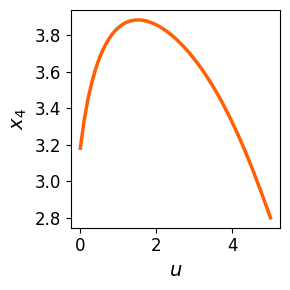

In [16]:
fig, ax = plt.subplots(figsize=(3,3))
plt.plot(u_array, X_output_array[3,:], color=rgb_orange_norm, linestyle='-', linewidth=2.5)
plt.xlabel('$u$', fontsize=14)
plt.ylabel('$x_{4}$', fontsize=14)
ax.tick_params(axis="both", labelsize=12)

plt.tight_layout()

plt.show()

### Eigenvalues

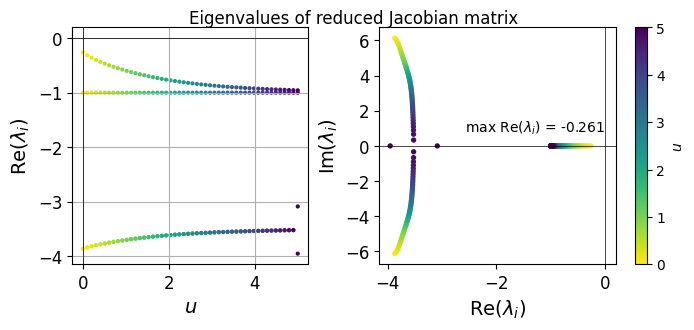

In [17]:

## eigenvalue plots:
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3))
U = np.tile(u_array, no_of_species)

ev = evals_output_array.ravel()
max_re = np.max(ev.real)
axis_max = 0.05
axis_max2 = 0.1

ax[0].scatter(U, np.real(evals_output_array), c=U,cmap='viridis_r', s=4, vmin=0, vmax=umax)
ax[0].grid(True)
ax[0].axhline(0, color='k', lw=0.5)
ax[0].axvline(0, color='k', lw=0.5)
ax[0].set_xlabel('$u$', fontsize=14)
ax[0].set_ylabel(r'Re($\lambda_i$)', fontsize=14)
ax[0].tick_params(axis="both", labelsize=12)


sc = ax[1].scatter(ev.real, ev.imag, c=U, cmap='viridis_r', s=8, vmin=0, vmax=umax)
ax[1].axvline(0, color='k', lw=0.5)      # stability boundary
ax[1].axhline(0, color='k', lw=0.5)
ax[1].set_xlabel(r'Re($\lambda_i$)', fontsize=14)
ax[1].set_ylabel(r'Im($\lambda_i$)', fontsize=14)


ax[1].tick_params(axis="both", labelsize=12)

cax = ax[1].inset_axes([1.08, 0, 0.05, 1])
cbar = fig.colorbar(sc, cax=cax, label='$u$')
fig.subplots_adjust(right=0.85, wspace=0.3, hspace=0.3)

ax[1].annotate(rf'max Re($\lambda_i$) = {max_re:.3g}', xy=(-0.005, 0),
                 xytext=(0, 10), textcoords='offset points',
                 ha='right', fontsize=10);
plt.suptitle('Eigenvalues of reduced Jacobian matrix', y=0.96)
fig.subplots_adjust(top=0.90)

plt.show()